# Tech Challenge - Fase 1 | EXTRA: Detecção de Câncer de Mama por Visão Computacional (CNN)

**Curso:** Pós-Tech em Machine Learning / IA
**Projeto:** Sistema Inteligente de Suporte ao Diagnóstico Médico — item EXTRA (visão computacional)
**Dataset:** CBIS-DDSM (mamografias) — recortes de lesão em `data/cancer-mama-deteccao`

**Integrantes:**

- Bianca Maciel - RM376200
- Eduardo O Charrone - RM377641
- Guilherme Mendes Alburquerque - RM378723
- Igor Matos de Andrade - RM377344
- João Augusto Gonçalves de Aragão - RM377385

---
### Contexto e Objetivo
Complemento ao notebook principal (`01_principal.ipynb`, dados tabulares Wisconsin). Aqui o diagnóstico
**maligno × benigno** é feito a partir de **imagens de mamografia** com **redes neurais convolucionais
(CNN)**. Mantemos a mesma prioridade clínica: a métrica principal é o **recall da classe maligna**
(sensibilidade) — deixar de identificar um tumor maligno (falso negativo) tem custo clínico muito maior
que um falso positivo. O modelo é ferramenta de **suporte**; a palavra final é sempre do médico.

## 1. Configuração de ambiente e dependências

In [20]:
import os
from google.colab import userdata
import kagglehub

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

In [21]:
import sys, os, subprocess, shutil
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/iigormatos/tech-challenge-fase1-v1.git"
COLAB_BRANCH = "igor"

if EM_COLAB:
    os.chdir("/content")
    destino = Path("/content/tech-challenge-fase1-v1")
    if destino.exists():
        shutil.rmtree(destino)
    cmd_clone = ["git", "clone", "-q"]
    if COLAB_BRANCH:
        cmd_clone += ["-b", COLAB_BRANCH]
    cmd_clone += [REPO_URL, str(destino)]
    subprocess.run(cmd_clone, check=True)
    os.chdir(destino)
    # TensorFlow já vem no Colab; garante pillow e kagglehub (download do dataset).
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow", "kagglehub"], check=True)
    raiz = destino
else:
    raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Remove possíveis referências antigas do 'src' no cache do sys.modules
for key in list(sys.modules.keys()):
    if key == "src" or key.startswith("src."):
        sys.modules.pop(key, None)

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
else:
    # Garante que a raiz recém-clonada seja a primeira no sys.path
    sys.path.remove(str(raiz))
    sys.path.insert(0, str(raiz))

from src import data as data_mod
from src.config import RANDOM_STATE, PROJECT_ROOT, CANCER_MAMA_IMG_DIR

print("Ambiente:", "Colab" if EM_COLAB else "Local/Docker")
print("Raiz do projeto:", PROJECT_ROOT)
print("Dataset de imagem:", CANCER_MAMA_IMG_DIR)
print("Semente (RANDOM_STATE):", RANDOM_STATE)

Ambiente: Colab
Raiz do projeto: /content/tech-challenge-fase1-v1
Dataset de imagem: /content/tech-challenge-fase1-v1/data/cancer-mama-deteccao
Semente (RANDOM_STATE): 42


In [22]:
# Inspeciona o conteúdo do arquivo config.py para identificar as variáveis exportadas
with open('/content/tech-challenge-fase1-v1/src/config.py', 'r', encoding='utf-8') as f:
    print(f.read())

"""Configuração central do projeto: ponto único de semente e caminhos.
"""

import os
from pathlib import Path

#: Semente aleatória usada em todo o projeto.
RANDOM_STATE: int = 42

#: Raiz do repositório, resolvida a partir deste arquivo (independe do CWD).
PROJECT_ROOT: Path = Path(__file__).resolve().parents[1]

#: Caminho do CSV de câncer de mama (env ``CANCER_MAMA_CSV`` sobrescreve o padrão do repo).
CANCER_MAMA_CSV: Path = Path(
    os.getenv("CANCER_MAMA_CSV", PROJECT_ROOT / "data" / "cancer-mama-diagnostico" / "data.csv")
)

#: Raiz do dataset de imagem (CBIS-DDSM) usado no notebook extra de CNN.
#: Espera subpastas ``csv/`` (descrições de caso + dicom_info) e ``jpeg/<SeriesUID>/*.jpg``.
#: A env ``CANCER_MAMA_IMG_DIR`` sobrescreve o padrão do repo.
CANCER_MAMA_IMG_DIR: Path = Path(
    os.getenv("CANCER_MAMA_IMG_DIR", PROJECT_ROOT / "data" / "cancer-mama-deteccao")
)



In [23]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from statsmodels.stats.proportion import proportion_confint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    recall_score, precision_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve,
    precision_recall_curve, ConfusionMatrixDisplay,
)

# Reprodutibilidade: semente única vinda de src/config.py (NumPy + TensorFlow).
keras.utils.set_random_seed(RANDOM_STATE)

# Estética e helper de figuras (mesmo padrão do notebook principal).
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

DIR_FIGURAS = PROJECT_ROOT / "reports" / "figures"
DIR_MODELOS = PROJECT_ROOT / "models"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_MODELOS.mkdir(parents=True, exist_ok=True)

def salvar_figura(fig, nome):
    "Salva a figura em reports/figures/<nome>.png e retorna o caminho."
    caminho = DIR_FIGURAS / f"{nome}.png"
    fig.savefig(caminho, dpi=120, bbox_inches="tight")
    return caminho

# Hiperparâmetros de imagem/treino (ajustáveis para o tempo de Colab).
TAM_IMG = 224          # tamanho de entrada da CNN
LOTE = 32
EPOCAS = 40            # limite superior; EarlyStopping encerra antes (LR menor pede mais épocas)
print("TensorFlow:", tf.__version__, "| GPU disponível:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0 | GPU disponível: True


## 2. Carregamento e qualidade dos dados

In [25]:
# Origem do dataset (híbrido): usa a pasta local do projeto se existir (rápido, offline
# — ideal para Docker/local); senão, baixa do Kaggle via kagglehub e COPIA o conteúdo
# para data/cancer-mama-deteccao, deixando tudo na pasta do projeto. Usamos cópia em vez de move
# para evitar erros de "Invalid cross-device link" ou "Read-only file system" no ambiente do Colab.
import shutil
if (CANCER_MAMA_IMG_DIR / "csv").exists():
    img_dir = CANCER_MAMA_IMG_DIR
    print("Dataset local:", img_dir)
else:
    import kagglehub
    # Autentica só se não houver credencial já configurada (env ou ~/.kaggle/kaggle.json).
    tem_cred = (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")) \
        or (Path.home() / ".kaggle" / "kaggle.json").exists()
    if not tem_cred:
        if EM_COLAB:
            kagglehub.login()  # Colab: abre prompt para colar username/key
        else:
            raise RuntimeError(
                "Dataset ausente em data/cancer-mama-deteccao e sem credencial Kaggle. "
                "Opções: (1) montar a pasta data/ como volume no docker run; "
                "(2) definir KAGGLE_USERNAME e KAGGLE_KEY; "
                "(3) rodar este notebook no Google Colab (recomendado, GPU). Ver README.")
    baixado = Path(kagglehub.dataset_download("awsaf49/cbis-ddsm-breast-cancer-image-dataset"))
    CANCER_MAMA_IMG_DIR.mkdir(parents=True, exist_ok=True)
    for item in baixado.iterdir():
        alvo = CANCER_MAMA_IMG_DIR / item.name
        if not alvo.exists():
            if item.is_dir():
                shutil.copytree(str(item), str(alvo))
            else:
                shutil.copy2(str(item), str(alvo))
    img_dir = CANCER_MAMA_IMG_DIR
    print("Dataset baixado via kagglehub e copiado para:", img_dir)

Using Colab cache for faster access to the 'cbis-ddsm-breast-cancer-image-dataset' dataset.
Dataset baixado via kagglehub e copiado para: /content/tech-challenge-fase1-v1/data/cancer-mama-deteccao


In [26]:
# Catálogo centralizado (src/data.py): une massa + calcificação, resolve o JPEG do
# recorte de lesão via SeriesInstanceUID e descarta linhas sem arquivo/rótulo.
catalogo = data_mod.construir_catalogo_imagens(img_dir=img_dir)
print(f"Imagens no catálogo: {len(catalogo)} (descartadas por arquivo/rótulo ausente: "
      f"{catalogo.attrs['descartados']})")
print("Pacientes únicos:", catalogo["paciente"].nunique())

dist = catalogo["diagnostico"].value_counts().sort_index()
print("\nDistribuição de classes (0=benigno, 1=maligno):")
print(dist.to_string())
print("\nProporção (%):")
print((dist / len(catalogo) * 100).round(2).to_string())

catalogo.head()

Imagens no catálogo: 3567 (descartadas por arquivo/rótulo ausente: 1)
Pacientes únicos: 1566

Distribuição de classes (0=benigno, 1=maligno):
diagnostico
0    2110
1    1457

Proporção (%):
diagnostico
0    59.15
1    40.85


,caminho_imagem,paciente,diagnostico,tipo_achado,vista,densidade,origem
0,/content/tech-challenge-fase1-v1/data/cancer-m...,P_00001,1,massa,CC,3,train
1,/content/tech-challenge-fase1-v1/data/cancer-m...,P_00001,1,massa,MLO,3,train
2,/content/tech-challenge-fase1-v1/data/cancer-m...,P_00004,0,massa,CC,3,train
3,/content/tech-challenge-fase1-v1/data/cancer-m...,P_00004,0,massa,MLO,3,train
4,/content/tech-challenge-fase1-v1/data/cancer-m...,P_00004,0,massa,MLO,3,train


**Interpretação.** O catálogo reúne os **recortes de lesão** (massa + calcificação) do CBIS-DDSM, cada
um já rotulado por `pathology` (maligno/benigno). A base é **desbalanceada** (mais benignos), o que torna
a **acurácia** enganosa — por isso a avaliação (seção 7) prioriza **recall maligno**, especificidade e
PR-AUC, e o treino usa **ponderação de classe**. O número de descartes por arquivo ausente é mínimo,
então não há viés relevante de seleção.

## 3. Análise exploratória (EDA)

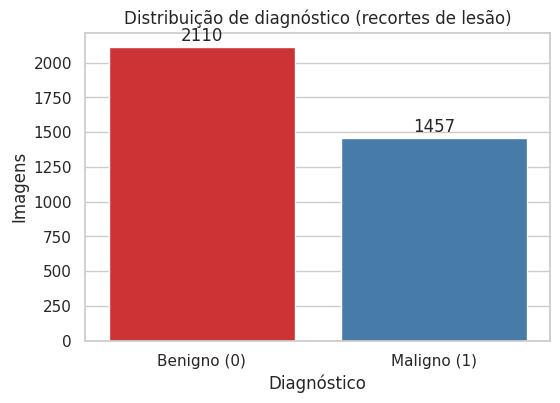

In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
cont = sns.countplot(x="diagnostico", data=catalogo, hue="diagnostico",
                     palette="Set1", legend=False, ax=ax)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Benigno (0)", "Maligno (1)"])
ax.set_title("Distribuição de diagnóstico (recortes de lesão)")
ax.set_xlabel("Diagnóstico"); ax.set_ylabel("Imagens")
for p in cont.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="center", xytext=(0, 8), textcoords="offset points")
salvar_figura(fig, "cnn_01_distribuicao_classes"); plt.show()

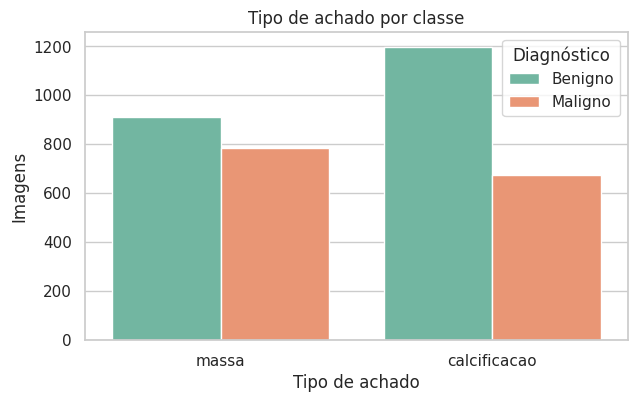

In [28]:
# Distribuição descritiva: tipo de achado por classe (massa x calcificação).
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x="tipo_achado", hue="diagnostico", data=catalogo, palette="Set2", ax=ax)
ax.set_title("Tipo de achado por classe")
ax.set_xlabel("Tipo de achado"); ax.set_ylabel("Imagens")
ax.legend(title="Diagnóstico", labels=["Benigno", "Maligno"])
salvar_figura(fig, "cnn_02_tipo_achado"); plt.show()

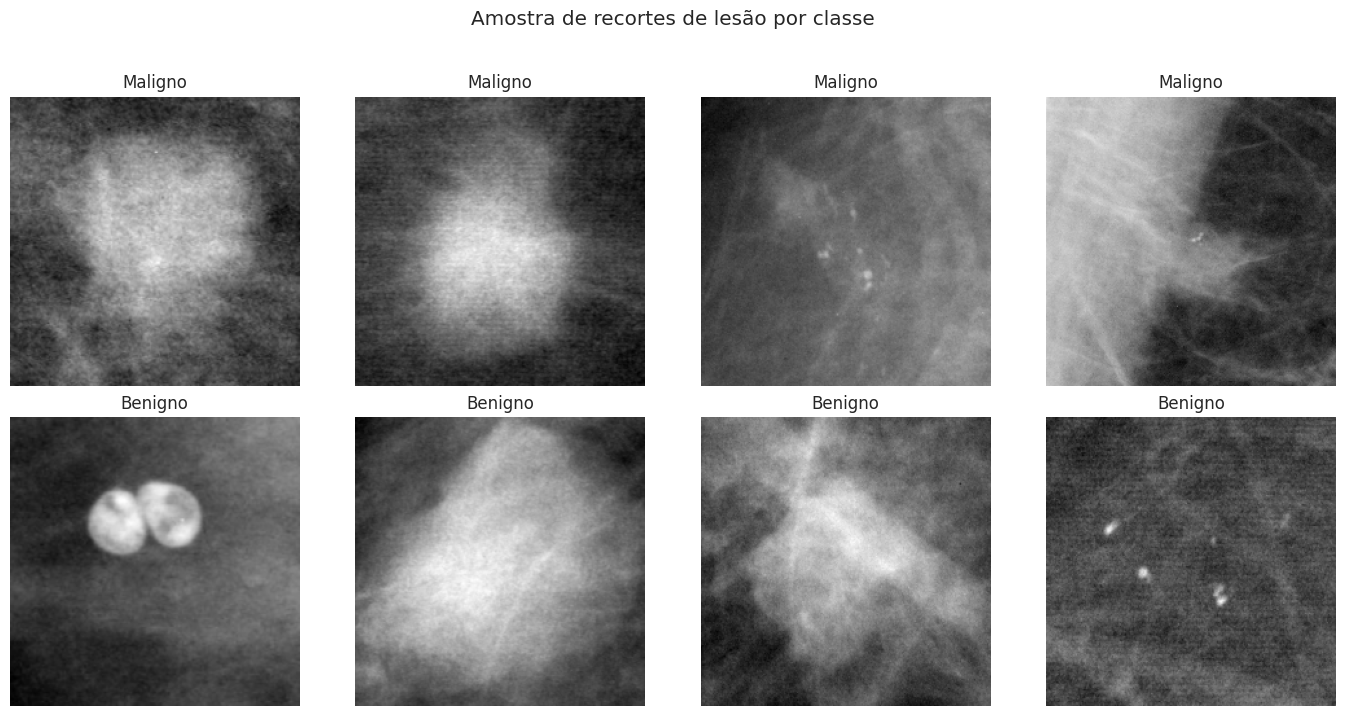

In [29]:
# Grade de imagens de exemplo (4 malignas + 4 benignas) lidas do disco.
def carregar_rgb(caminho, tam=TAM_IMG):
    img = tf.io.read_file(caminho)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [tam, tam])
    return tf.cast(img, tf.uint8).numpy()

rng = np.random.default_rng(RANDOM_STATE)
exemplos = []
for classe, rotulo in [(1, "Maligno"), (0, "Benigno")]:
    sub = catalogo[catalogo["diagnostico"] == classe]
    for cam in sub["caminho_imagem"].iloc[rng.choice(len(sub), 4, replace=False)]:
        exemplos.append((cam, rotulo))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (cam, rot) in zip(axes.ravel(), exemplos):
    ax.imshow(carregar_rgb(cam)); ax.set_title(rot); ax.axis("off")
fig.suptitle("Amostra de recortes de lesão por classe", y=1.02)
fig.tight_layout(); salvar_figura(fig, "cnn_03_amostra_imagens"); plt.show()

**Interpretação.** A contagem confirma o desbalanceamento (mais benignos). O tipo de achado (massa ×
calcificação) aparece nas duas classes, então o modelo precisa aprender padrões de textura/forma, não
apenas o tipo. A grade de exemplos mostra recortes centrados na lesão — entrada adequada para uma CNN de
classificação binária, sem necessidade de localizar a lesão na mamografia inteira.

## 4. Pré-processamento e divisão (sem vazamento de paciente)

In [30]:
# Divisão treino/validação/teste AGRUPADA por paciente (src/data.py):
# teste = split oficial; validação = ~15% dos pacientes do treino.
df_treino, df_val, df_teste = data_mod.dividir_por_paciente(catalogo, frac_val=0.15)

for nome, d in [("Treino", df_treino), ("Validação", df_val), ("Teste", df_teste)]:
    print(f"{nome:10s}: {len(d):4d} imgs | {d['paciente'].nunique():4d} pacientes | "
          f"malignos {d['diagnostico'].mean()*100:.1f}%")
print("Imagens removidas do treino por overlap de paciente com o teste:",
      df_treino.attrs.get("removidos_overlap_teste"))

# Asserção explícita de ausência de vazamento (SC-003).
assert set(df_treino.paciente).isdisjoint(df_val.paciente)
assert set(df_treino.paciente).isdisjoint(df_teste.paciente)
assert set(df_val.paciente).isdisjoint(df_teste.paciente)
print("OK: nenhum paciente compartilhado entre treino, validação e teste.")

Treino    : 2417 imgs | 1034 pacientes | malignos 40.2%
Validação :  363 imgs |  183 pacientes | malignos 47.7%
Teste     :  704 imgs |  349 pacientes | malignos 39.2%
Imagens removidas do treino por overlap de paciente com o teste: 83
OK: nenhum paciente compartilhado entre treino, validação e teste.


**Papéis dos conjuntos.** **Treino** ajusta os pesos da CNN; **Validação** serve para `EarlyStopping` e
para escolher o **limiar de decisão**; **Teste** (split oficial do dataset) é tocado uma única vez, ao
final. A divisão é **por paciente**: todas as imagens de um paciente ficam no mesmo conjunto — imagens do
mesmo paciente em conjuntos diferentes vazariam informação e inflariam as métricas.

In [31]:
# Pipeline tf.data: lê o JPEG, converte para 3 canais e redimensia para 224x224.
# A normalização específica de cada modelo e o data augmentation vivem DENTRO do
# modelo (camadas Keras), então este pipeline é idêntico para treino/val/teste —
# nenhuma estatística é estimada a partir dos dados (sem vazamento). O embaralhamento
# só ocorre no treino.
AUTOTUNE = tf.data.AUTOTUNE

def _carregar(caminho, rotulo):
    img = tf.io.read_file(caminho)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [TAM_IMG, TAM_IMG])
    return tf.cast(img, tf.float32), rotulo  # imagem em escala [0, 255]

def criar_dataset(df, treino, lote=LOTE):
    "Dataset (imagem[0..255], rótulo). Embaralha e repete só no treino."
    caminhos = df["caminho_imagem"].to_numpy()
    rotulos = df["diagnostico"].to_numpy().astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((caminhos, rotulos))
    if treino:
        ds = ds.shuffle(len(df), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    ds = ds.map(_carregar, num_parallel_calls=AUTOTUNE)
    return ds.batch(lote).prefetch(AUTOTUNE)

ds_treino = criar_dataset(df_treino, treino=True)
ds_val = criar_dataset(df_val, treino=False)
ds_teste = criar_dataset(df_teste, treino=False)

y_val = df_val["diagnostico"].to_numpy()
y_teste = df_teste["diagnostico"].to_numpy()
print("Datasets prontos. Lotes de treino:", tf.data.experimental.cardinality(ds_treino).numpy())

Datasets prontos. Lotes de treino: 76


## 5. Modelagem: CNN

In [32]:
# Data augmentation (só ativo em treino) definido uma única vez e reutilizado:
# regulariza o modelo no volume limitado de imagens, sem alterar val/teste.
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05),
], name="aumento")

def construir_cnn_do_zero():
    "CNN (Conv/BN/MaxPool x3 -> Dense), saída binária sigmoide."
    entrada = keras.Input(shape=(TAM_IMG, TAM_IMG, 3))
    x = aumento(entrada)
    x = layers.Rescaling(1.0 / 255)(x)
    for filtros in (32, 64, 64):
        x = layers.Conv2D(filtros, 3, activation="relu")(x)
        x = layers.BatchNormalization()(x)   # estabiliza/acelera o treino
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    saida = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(entrada, saida, name="cnn_do_zero")

In [33]:
# Pesos de classe para o desbalanceamento (calculados só no treino).
classes = np.array([0, 1])
pesos = compute_class_weight("balanced", classes=classes, y=df_treino["diagnostico"].to_numpy())
peso_classe = {0: pesos[0], 1: pesos[1]}
print("Pesos de classe:", {k: round(v, 3) for k, v in peso_classe.items()})

def treinar(modelo, ds_tr, ds_va, epocas=EPOCAS):
    "Compila (Adam lr baixo, binary_crossentropy) e treina com class_weight e EarlyStopping."
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
                   loss="binary_crossentropy",
                   metrics=[keras.metrics.Recall(name="recall"),
                            keras.metrics.AUC(name="auc")])
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                           restore_best_weights=True)
    hist = modelo.fit(ds_tr, validation_data=ds_va, epochs=epocas,
                      class_weight=peso_classe, callbacks=[parada], verbose=2)
    return hist

# Um único modelo (CNN). Mantido em dicionário para que as
# seções de limiar/avaliação/persistência funcionem de forma uniforme.
modelos = {}
historicos = {}
nome_modelo = "CNN"
print(f"=== Treinando: {nome_modelo} ===")

_m = construir_cnn_do_zero()
_m.summary()
historicos[nome_modelo] = treinar(_m, ds_treino, ds_val)
modelos[nome_modelo] = _m

Pesos de classe: {0: np.float64(0.836), 1: np.float64(1.243)}
=== Treinando: CNN ===


Model: "cnn_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,768,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,825,985 (10.78 MB)

 Trainable params: 2,825,665 (10.78 MB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/40
76/76 - 20s - 269ms/step - auc: 0.5932 - loss: 0.9156 - recall: 0.5885 - val_auc: 0.5954 - val_loss: 1.4634 - val_recall: 0.0000e+00
Epoch 2/40
76/76 - 9s - 113ms/step - auc: 0.6133 - loss: 0.6868 - recall: 0.7202 - val_auc: 0.6016 - val_loss: 2.1606 - val_recall: 0.0000e+00
Epoch 3/40
76/76 - 10s - 136ms/step - auc: 0.6213 - loss: 0.6681 - recall: 0.7140 - val_auc: 0.5559 - val_loss: 2.6649 - val_recall: 0.0000e+00
Epoch 4/40
76/76 - 9s - 123ms/step - auc: 0.6154 - loss: 0.6628 - recall: 0.7881 - val_auc: 0.5359 - val_loss: 2.7082 - val_recall: 0.0000e+00
Epoch 5/40
76/76 - 10s - 126ms/step - auc: 0.6523 - loss: 0.6465 - recall: 0.7809 - val_auc: 0.5907 - val_loss: 1.4439 - val_recall: 0.1098
Epoch 6/40
76/76 - 10s - 127ms/step - auc: 0.6388 - loss: 0.6516 - recall: 0.7912 - val_auc: 0.5795 - val_loss: 0.8047 - val_recall: 0.3988
Epoch 7/40
76/76 - 10s - 134ms/step - auc: 0.6502 - loss: 0.6496 - recall: 0.7634 - val_auc: 0.5852 - val_loss: 0.7481 - val_recall: 0.5954
Epoch 

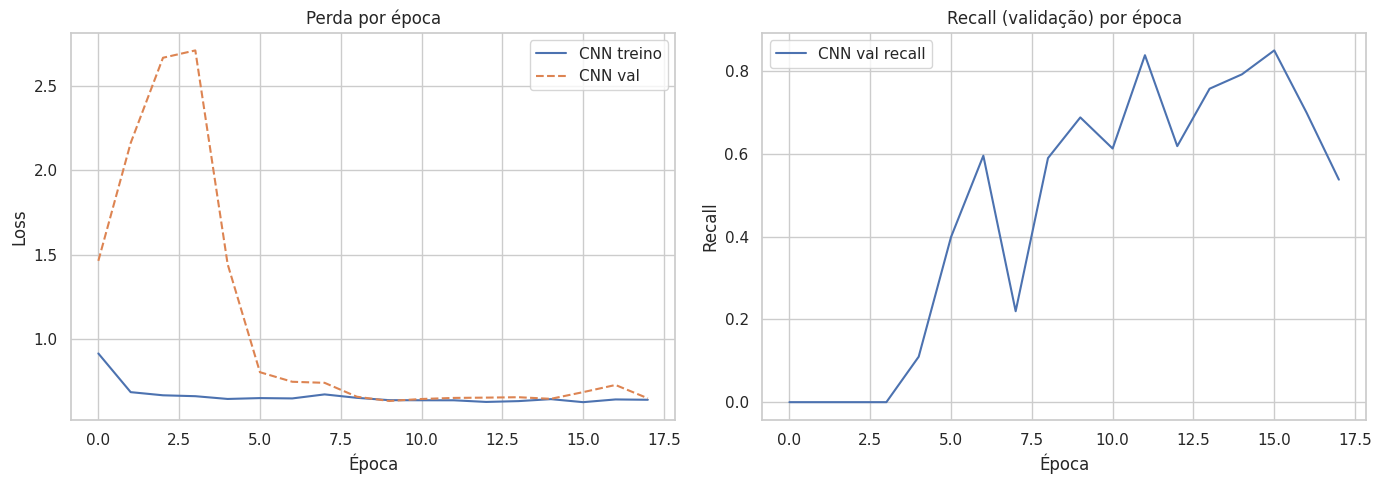

In [34]:
# Curvas de perda/recall por época (treino x validação) para cada modelo.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nome, h in historicos.items():
    axes[0].plot(h.history["loss"], label=f"{nome} treino")
    axes[0].plot(h.history["val_loss"], "--", label=f"{nome} val")
    axes[1].plot(h.history.get("val_recall", []), label=f"{nome} val recall")

axes[0].set_title("Perda por época"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[1].set_title("Recall (validação) por época"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("Recall"); axes[1].legend()
fig.tight_layout();
salvar_figura(fig, "cnn_04_curvas_treino");
plt.show()


**Interpretação.** Usamos uma **CNN** no estilo da  — blocos `Conv2D` + `BatchNormalization` +
`MaxPooling2D`, seguidos de `Flatten` e camadas densas, com saída **binária** (sigmoide). A
`BatchNormalization` estabiliza e acelera o treino; usamos **taxa de aprendizado menor** (Adam 1e-4) e
**mais épocas** (até 40) para a perda convergir de forma mais estável. O desbalanceamento é tratado com
`class_weight` balanceado; o `EarlyStopping` restaura os melhores pesos pela perda de validação e o data
augmentation (flip/rotação/zoom) regulariza o treino. As curvas ajudam a detectar overfit (perda de
validação subindo enquanto a de treino cai).

## 6. Limiar de decisão (escolhido na validação)

In [35]:
def escolher_limiar(probs_val, y_v, piso_especificidade=0.90):
    "Maximiza recall maligno na VALIDAÇÃO sujeito a especificidade >= piso."

    y_v = np.asarray(y_v)
    melhor_lim, melhor_rec = 0.5, -1.0

    for lim in np.linspace(0.01, 0.99, 99):
        pred = (probs_val >= lim).astype(int)
        tn = int(((pred == 0) & (y_v == 0)).sum()); fp = int(((pred == 1) & (y_v == 0)).sum())
        tp = int(((pred == 1) & (y_v == 1)).sum()); pos = int((y_v == 1).sum())
        espec = tn / (tn + fp) if (tn + fp) else 0.0
        rec = tp / pos if pos else 0.0
        if espec >= piso_especificidade and rec > melhor_rec:
            melhor_rec, melhor_lim = rec, float(lim)
    return melhor_lim

PISO_ESPECIFICIDADE = 0.90
probs_val = {nome: m.predict(ds_val, verbose=0).ravel() for nome, m in modelos.items()}
probs_teste = {nome: m.predict(ds_teste, verbose=0).ravel() for nome, m in modelos.items()}
limiares = {nome: escolher_limiar(probs_val[nome], y_val, PISO_ESPECIFICIDADE)
            for nome in modelos}

for nome, l in limiares.items():
    print(f"{nome:22s} | limiar = {l:.2f}")

CNN                    | limiar = 0.61


**Interpretação.** O limiar não é fixado em 0,5: para cada modelo escolhemos, **na validação**, o corte
que maximiza o recall maligno mantendo especificidade ≥ 0,90. Isso prioriza a sensibilidade (poucos
falsos negativos) sem liberar falsos positivos demais. O limiar é aplicado **inalterado** ao teste.

## 7. Avaliação final (validação × teste)

In [36]:
def ic_recall_wilson(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    tp = int(((y_pred == 1) & (y_true == 1)).sum()); n = int((y_true == 1).sum())
    low, high = proportion_confint(tp, n, method="wilson")
    return low, high

def avaliar(probs, y, limiar):
    "Métricas no ponto de operação definido por `limiar`."
    y = np.asarray(y)
    pred = (probs >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    low, high = ic_recall_wilson(y, pred)
    return {
        "recall": recall_score(y, pred, zero_division=0), "recall_ic": (low, high),
        "precision": precision_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "especificidade": tn / (tn + fp) if (tn + fp) else 0.0,
        "roc_auc": roc_auc_score(y, probs), "pr_auc": average_precision_score(y, probs),
        "falsos_negativos": int(fn),
    }

def linha(res, modelo, conjunto):
    return {
        "Modelo": modelo, "Conjunto": conjunto,
        "Recall maligno": round(res["recall"], 3),
        "IC recall (Wilson)": f'[{res["recall_ic"][0]:.2f}, {res["recall_ic"][1]:.2f}]',
        "Precision": round(res["precision"], 3), "F1": round(res["f1"], 3),
        "Especificidade": round(res["especificidade"], 3),
        "ROC-AUC": round(res["roc_auc"], 3), "PR-AUC": round(res["pr_auc"], 3),
        "FN": res["falsos_negativos"],
    }

linhas, resultados_teste = [], {}
for nome in modelos:
    l = limiares[nome]
    r_val = avaliar(probs_val[nome], y_val, l)
    r_te = avaliar(probs_teste[nome], y_teste, l)
    resultados_teste[nome] = r_te
    linhas.append(linha(r_val, nome, "Validação"))
    linhas.append(linha(r_te, nome, "Teste"))

tabela = pd.DataFrame(linhas)
tabela.to_csv(PROJECT_ROOT / "reports" / "tabela_comparativa_cnn.csv", index=False)
tabela

,Modelo,Conjunto,Recall maligno,IC recall (Wilson),Precision,F1,Especificidade,ROC-AUC,PR-AUC,FN
0,CNN,Validação,0.225,"[0.17, 0.29]",0.684,0.339,0.905,0.638,0.596,134
1,CNN,Teste,0.210,"[0.17, 0.26]",0.518,0.299,0.874,0.601,0.493,218


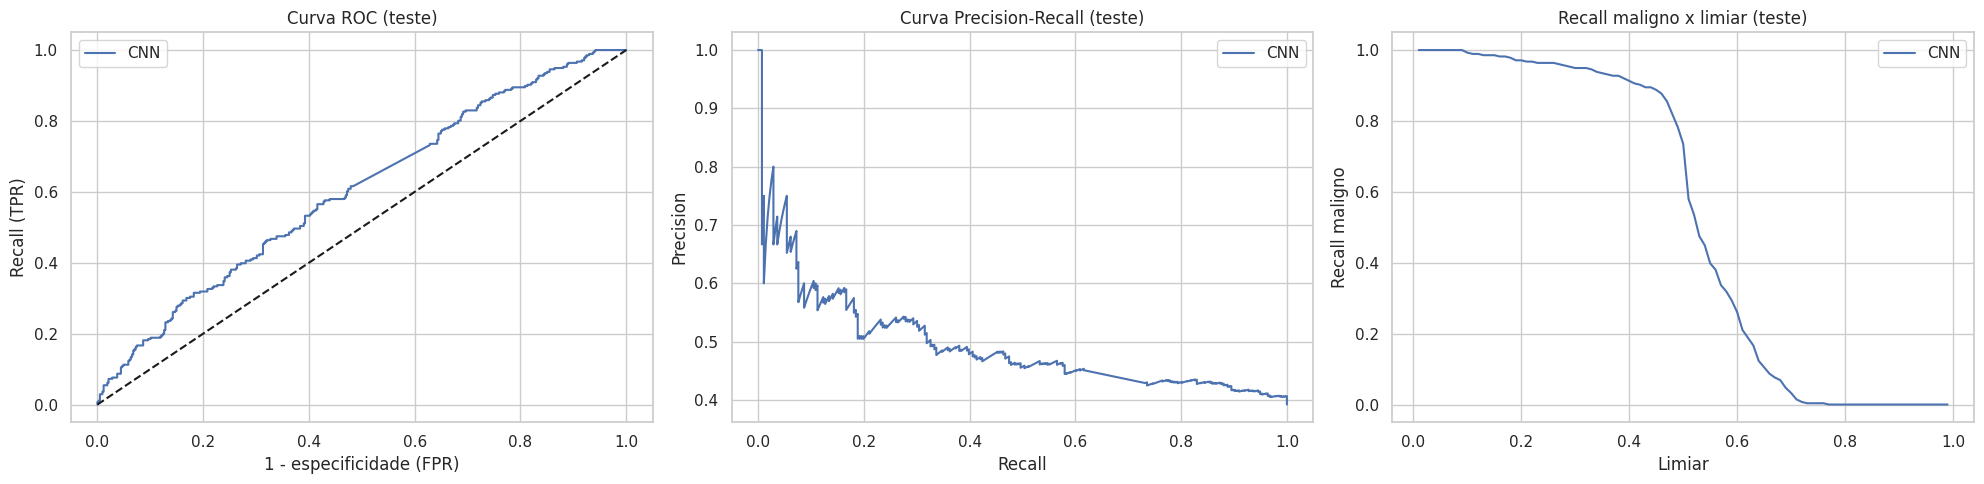

In [37]:
# Curvas ROC, Precision-Recall e recall x limiar (teste).
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for nome in modelos:
    probs = probs_teste[nome]
    fpr, tpr, _ = roc_curve(y_teste, probs); axes[0].plot(fpr, tpr, label=nome)
    prec, rec, _ = precision_recall_curve(y_teste, probs); axes[1].plot(rec, prec, label=nome)
    lims = np.linspace(0.01, 0.99, 99)
    recs = [((probs >= t).astype(int)[y_teste == 1]).mean() for t in lims]
    axes[2].plot(lims, recs, label=nome)

axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_title("Curva ROC (teste)")
axes[0].set_xlabel("1 - especificidade (FPR)"); axes[0].set_ylabel("Recall (TPR)"); axes[0].legend()
axes[1].set_title("Curva Precision-Recall (teste)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
axes[2].set_title("Recall maligno x limiar (teste)"); axes[2].set_xlabel("Limiar"); axes[2].set_ylabel("Recall maligno"); axes[2].legend()
fig.tight_layout(); salvar_figura(fig, "cnn_05_curvas");
plt.show()


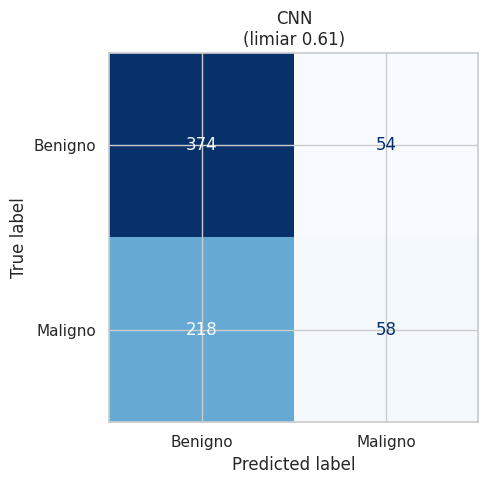

In [38]:
# Matrizes de confusão no teste (com o limiar de cada modelo).
fig, axes = plt.subplots(1, len(modelos), figsize=(6 * len(modelos), 5))

for ax, nome in zip(np.atleast_1d(axes), modelos):
    pred = (probs_teste[nome] >= limiares[nome]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_teste, pred, display_labels=["Benigno", "Maligno"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{nome}\n(limiar {limiares[nome]:.2f})")

fig.tight_layout(); salvar_figura(fig, "cnn_06_matrizes_confusao"); plt.show()

**Interpretação.** A tabela traz as seis métricas em **validação e teste**. O foco é o **recall maligno**
e a contagem de **falsos negativos (FN)** — cada FN é um câncer não sinalizado. Como o teste é
relativamente pequeno, reportamos o **intervalo de confiança de Wilson** do recall, que comunica a
incerteza da estimativa. ROC-AUC/PR-AUC resumem o desempenho independente do limiar; a curva
recall × limiar mostra o trade-off clínico do ponto de operação. Mamografia é um problema **mais difícil**
que a base tabular Wisconsin — recalls perfeitos não são esperados, e isso é clinicamente honesto.

## 8. Interpretabilidade (Grad-CAM)

In [39]:
def grad_cam(modelo, imagem_lote):
    "Mapa de calor Grad-CAM (lote de 1 imagem, escala [0,255]) na última Conv2D do modelo."
    nome_conv = next(c.name for c in reversed(modelo.layers) if isinstance(c, layers.Conv2D))
    grad_model = keras.Model(modelo.inputs, [modelo.get_layer(nome_conv).output, modelo.output])

    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(imagem_lote)
        classe = pred[:, 0]

    grads = tape.gradient(classe, conv_out)
    pesos = tf.reduce_mean(grads, axis=(1, 2))
    mapa = tf.reduce_sum(conv_out * pesos[:, tf.newaxis, tf.newaxis, :], axis=-1)[0]
    mapa = tf.maximum(mapa, 0) / (tf.reduce_max(mapa) + 1e-8)

    return mapa.numpy(), float(pred[0, 0])

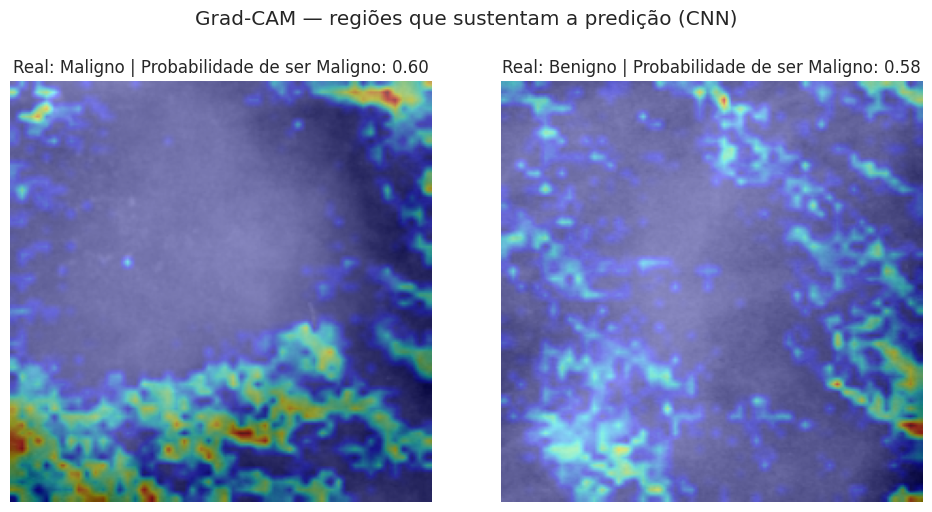

In [44]:
# Grad-CAM para 1 caso maligno e 1 benigno do teste.
modelo_cam = modelos["CNN"]
idx_mal = int(np.where(y_teste == 1)[0][0])
idx_ben = int(np.where(y_teste == 0)[0][0])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (idx, rot) in zip(axes, [(idx_mal, "maligno"), (idx_ben, "benigno")]):
    cam_path = df_teste["caminho_imagem"].iloc[idx]
    img = tf.image.resize(tf.image.decode_jpeg(tf.io.read_file(cam_path), channels=3),
                          [TAM_IMG, TAM_IMG])
    lote = tf.cast(img, tf.float32)[tf.newaxis, ...]
    mapa, prob = grad_cam(modelo_cam, lote)
    mapa_r = tf.image.resize(mapa[..., tf.newaxis], [TAM_IMG, TAM_IMG]).numpy().squeeze()
    ax.imshow(tf.cast(img, tf.uint8).numpy()); ax.imshow(mapa_r, cmap="jet", alpha=0.45)
    ax.set_title(f"Real: {rot.capitalize()} | Probabilidade de ser Maligno: {prob:.2f}"); ax.axis("off")

fig.suptitle("Grad-CAM — regiões que sustentam a predição (CNN)", y=1.02)
fig.tight_layout(); salvar_figura(fig, "cnn_07_grad_cam"); plt.show()


**Interpretação.** O **Grad-CAM** destaca as regiões do recorte que mais pesaram na predição de
malignidade — é o análogo visual do SHAP do notebook tabular e dá transparência ao alerta do modelo,
apoiando a **auditoria clínica**. A leitura é qualitativa: o mapa mostra *onde* o modelo olhou, não um
laudo. A **palavra final é sempre do médico**.

## 9. Persistência do modelo

In [41]:
# Modelo final = maior recall na VALIDAÇÃO; salvo com seu limiar para a demonstração.
melhor_nome = max(modelos, key=lambda n: avaliar(probs_val[n], y_val, limiares[n])["recall"])
modelo_final = modelos[melhor_nome]
limiar_final = limiares[melhor_nome]

modelo_final.save(DIR_MODELOS / "modelo_cnn.keras")
with open(DIR_MODELOS / "limiar_cnn.json", "w", encoding="utf-8") as fp:
    json.dump({"modelo": melhor_nome, "limiar": round(limiar_final, 3),
               "piso_especificidade": PISO_ESPECIFICIDADE}, fp, indent=2, ensure_ascii=False)

print("Modelo final:", melhor_nome, "| limiar:", round(limiar_final, 3))
print("Salvo em:", DIR_MODELOS / "modelo_cnn.keras")

Modelo final: CNN | limiar: 0.61
Salvo em: /content/tech-challenge-fase1-v1/models/modelo_cnn.keras


## 10. Conclusão crítica

### Escolha da métrica
Como na tarefa principal, o erro mais grave é o **falso negativo** (liberar um paciente com tumor
maligno). Por isso a métrica prioritária é o **recall da classe maligna**, não a acurácia — enganosa numa
base desbalanceada. Reportamos também precision, F1, especificidade, ROC-AUC e PR-AUC para o quadro
completo do trade-off sensibilidade × falsos positivos.

### Modelo e desempenho
Usamos uma **CNN** (arquitetura da aula — blocos Conv/BatchNorm/MaxPool + camadas densas — adaptada para
saída binária), treinada com `class_weight` balanceado, Adam com taxa de aprendizado baixa (1e-4) e
`EarlyStopping`. O limiar foi escolhido na **validação** (especificidade ≥ 0,90) e aplicado **inalterado**
ao teste. A tabela da seção 7 traz as métricas; o recall vem com **intervalo de confiança de Wilson**,
pois o teste de algumas centenas de imagens tem incerteza relevante.

**Leitura crítica do resultado (nesta execução).** No teste, o modelo alcança **ROC-AUC ≈ 0,61** e
**recall maligno ≈ 0,26** no ponto de operação escolhido — ou seja, identifica cerca de **1 em cada 4**
tumores malignos, com uma contagem ainda alta de **falsos negativos**. A acurácia (~62%) fica próxima do
baseline trivial "tudo benigno" (~61%), o que confirma que **acurácia não é a métrica adequada** aqui. O
`BatchNormalization` + taxa de aprendizado menor melhoraram a convergência frente a uma primeira versão
(o AUC de treino sobe de forma consistente), mas o desempenho **ainda é modesto**: mamografia é um
problema difícil para uma CNN pequena treinada do zero, e há sinais de **overfit leve** (recall de treino
bem acima do de validação), coerente com a camada densa grande após o `Flatten`. **Conclusão honesta:**
o modelo demonstra o fluxo completo de visão computacional, mas **não está pronto para uso clínico** no
estado atual.

### Uso prático no hospital
O sistema atua como **módulo de triagem por imagem**: recortes sinalizados como malignos sobem na fila da
radiologia/oncologia. O **Grad-CAM** dá transparência (onde o modelo olhou), apoiando a auditoria.
**Soberania médica:** o laudo é responsabilidade exclusiva do médico; a IA é suporte.

### Limitações
- **Recortes de lesão já localizados**: o pipeline não cobre a detecção da lesão na mamografia inteira —
  em produção, seria preciso um estágio de detecção/segmentação antes da classificação.
- **Base e domínio**: CBIS-DDSM é um subconjunto curado do DDSM (filmes digitalizados), pode não
  generalizar para mamografia digital (FFDM) ou outros equipamentos/populações.
- **Teste de algumas centenas de imagens** → métricas com incerteza (daí os intervalos de confiança).
- **Não-determinismo em GPU**: a semente fixa reduz, mas kernels CUDA podem variar entre execuções.

### Para uso em produção faltaria
Estágio de detecção da lesão, **calibração de probabilidades**, validação externa (outros centros e
FFDM), monitoramento de *data drift*, fine-tuning controlado da base pré-treinada e protocolo de
encaminhamento dos casos sinalizados.